<a href="https://colab.research.google.com/github/garvitSharma24112/machine-learning/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### PCA on Sample Data

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Generate sample data
np.random.seed(42)
n_samples = 150

# Create three correlated features
x1 = np.random.normal(loc=10, scale=2, size=n_samples)
x2 = x1 * 1.5 + np.random.normal(loc=0, scale=1, size=n_samples)
x3 = -x1 * 0.8 + np.random.normal(loc=0, scale=0.5, size=n_samples)

# Target label for visualization purposes
y = np.where(x1 > 10, 'Group A', 'Group B')

df = pd.DataFrame({'Feature_1': x1, 'Feature_2': x2, 'Feature_3': x3, 'Target': y})
display(df.head())

,Feature_1,Feature_2,Feature_3,Target
0,10.993428,16.740635,-9.209240,Group A
1,9.723471,14.931655,-8.058868,Group B
2,11.295377,16.263041,-8.662655,Group A
3,13.046060,19.801343,-10.131663,Group A
4,9.531693,14.590612,-7.635805,Group B


In [5]:
# 2. Standardize the features (Crucial step for PCA)
features = ['Feature_1', 'Feature_2', 'Feature_3']
x = df[features].values
x_scaled = StandardScaler().fit_transform(x)

# 3. Perform PCA (Reduce from 3D to 2D)
pca = PCA(n_components=2)
principal_components = pca.fit_transform(x_scaled)

pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['Target'] = df['Target']

print(f"Explained variance ratio per component: {pca.explained_variance_ratio_}")
print(f"Total explained variance: {sum(pca.explained_variance_ratio_):.2%}")

Explained variance ratio per component: [0.95289651 0.03591046]
Total explained variance: 98.88%


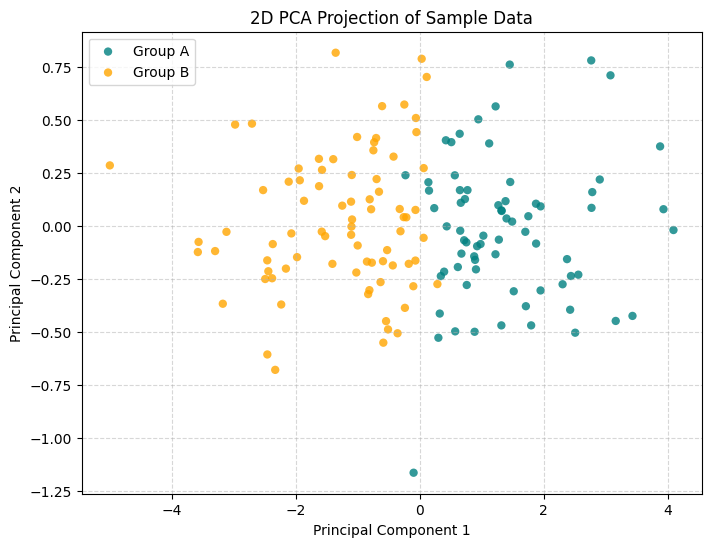

In [6]:
# 4. Plot the PCA components
fig = plt.figure(figsize=(8, 6))
colors = {'Group A': 'teal', 'Group B': 'orange'}

for target, color in colors.items():
    indices = pca_df['Target'] == target
    plt.scatter(pca_df.loc[indices, 'PC1'],
                pca_df.loc[indices, 'PC2'],
                c=color,
                label=target,
                alpha=0.8,
                edgecolors='none')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D PCA Projection of Sample Data')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()